# 8.7 Evaluating Adapted Models

**Module 8 · Note 7**

We have now adapted DistilBERT twice, fully in Note 8.4 and with LoRA in Note 8.5, and built a ladder of baselines in Note 8.3. Each note printed its own numbers. But a pile of numbers isn't an answer. The question that matters is: **did adaptation work well enough to use?** Answering it honestly takes more than reading off the highest score. We need to know whether the differences are real or noise, what kinds of mistakes each model makes, whether a model overfitted or forgot things it needed, what each method cost, and whether the results can be reproduced. Then we need a decision, made by rules we can defend, and a record of it.

This note does all of that, without training anything. It reads the results files saved by Notes 8.3–8.5, checks that every method was evaluated on exactly the same reviews, and walks through a complete evaluation, ending in a keep-or-reject decision.

**Key question:** *How do we know whether adaptation worked, and how do we decide whether to keep an adapted model?*

**By the end of this note you will be able to:**
- read training curves and explain what training and validation signals tell you;
- report task metrics with confidence intervals;
- analyse errors: which reviews each method gets wrong, where methods agree, and patterns in the failures;
- detect overfitting and catastrophic forgetting from saved results;
- compare methods on quality, trainable parameters, time and memory, with paired significance tests;
- measure run-to-run variation and track experiments;
- make and document a keep-or-reject decision by rules set in advance.

**Before you start:** run Notes 8.3, 8.4 and 8.5 first. This note reads their files in `results/`, and stops with a message if any is missing. It uses everything from Module 8, the sign test (Module 5) and the decision record from Note 7.7.

### Setup

This note trains no models, so it runs in seconds. The usual harmless warnings may appear, plus one "Token indices sequence length is longer than…" message in Section 4, where we count the full length of each test review on purpose.

In [1]:
import os, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers, peft
from scipy.stats import binomtest
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import AutoTokenizer

np.random.seed(0)
print("PyTorch", torch.__version__, "| Transformers", transformers.__version__, "| PEFT", peft.__version__)

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 23:21:19.379000 4811 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 23:21:19.471000 4811 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 23:21:19.490000 4811 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | Transformers 5.20.1 | PEFT 0.21.2


## 1. The Big Picture: How Do We Know Adaptation Worked?

"Worked" has several meanings, and a good evaluation checks each one:

| Question | Where it's answered |
|---|---|
| Did training behave sensibly? | training and validation curves (Section 2) |
| How good is the model, with what uncertainty? | task metrics with confidence intervals (Section 3) |
| What does it get wrong, and why? | error analysis (Section 4) |
| Did it overfit, or forget? | validation–test gaps, forgetting measure (Section 5) |
| Is it better than the alternatives, and at what cost? | the full comparison with paired tests (Section 6) |
| Would we get the same result again? | variation and tracking (Section 7) |
| Should we use it? | rules decided in advance (Section 8), then a written record (Section 9) |

> 🖼 *IMAGE 8.7.1 — Seven Questions Before Keeping a Model.* A vertical checklist card on a white background titled "Did adaptation work?", with seven rows, each with an icon: a line chart "training behaved?", a ruler with error bars "how good, how sure?", a magnifying glass over a red X "what does it get wrong?", a split arrow "overfit or forgot?", a balance scale "better than alternatives, at what cost?", a pair of dice "would it happen again?", a gavel "keep or reject, by rules set in advance". At the bottom, a folder icon "write it down". Takeaway: evaluating an adapted model means answering several questions, not reading one score.

### Loading the results

The fixed split is rebuilt with the same function as every other note. Then we load the three results files and check that each one used the same split *and* the same 1,000 training reviews. If not, comparing them would be meaningless, so the cell stops.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"})
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")
test_x, test_y = imdb["test_eval"]
train_x = imdb["train"][0][:1000]

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


In [4]:
need = {"8.3": "results/8.3.json", "8.4": "results/8.4.json", "8.5": "results/8.5.json"}
missing = [n for n, f in need.items() if not os.path.exists(f)]
assert not missing, f"run Note(s) {', '.join(missing)} first: their results files are missing"
files = {n: json.load(open(f)) for n, f in need.items()}
expected = {k: fingerprint(imdb[k][0]) for k in ("train", "val_eval", "test_eval")}
for n, rec in files.items():
    ok = rec["split_fingerprints"] == expected and rec["train_subset_fingerprint"] == fingerprint(train_x)
    print(f"Note {n}: same split and same 1,000 training reviews: {ok}")
    assert ok, f"Note {n} was run on different data: rerun it"

Note 8.3: same split and same 1,000 training reviews: True
Note 8.4: same split and same 1,000 training reviews: True
Note 8.5: same split and same 1,000 training reviews: True


All three notes ran on the same data. Here is everything they measured, side by side:

In [5]:
methods = {}
for name, r in files["8.3"]["rungs"].items():
    methods[name] = r
methods["full fine-tuning"] = files["8.4"]
methods["LoRA"] = files["8.5"]
for name, r in methods.items():
    print(f"{name:<40} labels {r['labels_used']:>6,} | val {r['val']['accuracy']:.3f} | test {r['test']['accuracy']:.3f}")

majority class                           labels  1,000 | val 0.505 | test 0.485
TF-IDF, 1,000 labels                     labels  1,000 | val 0.866 | test 0.828
TF-IDF, all labels                       labels 22,404 | val 0.921 | test 0.913
SST-2 model, off the shelf               labels      0 | val 0.888 | test 0.873
frozen DistilBERT + logistic regression  labels  1,000 | val 0.850 | test 0.837
full fine-tuning                         labels  1,000 | val 0.860 | test 0.834
LoRA                                     labels  1,000 | val 0.880 | test 0.834


Seven methods, all scored on the same 1,000 validation and 1,000 test reviews. The rest of this note works out what these numbers mean.

## 2. Training vs. Validation Loss

During training, two kinds of signal tell you whether things are going well. The **training loss** shows whether the model is fitting the data it learns from. A **validation signal**, validation loss or validation accuracy on data the model never trains on, shows whether that learning carries over to new data. Overfitting appears as the two pulling apart: training keeps improving while validation stalls or worsens (Note 8.1).

Notes 8.4 and 8.5 saved the training loss at every step and the validation accuracy at each checkpoint:

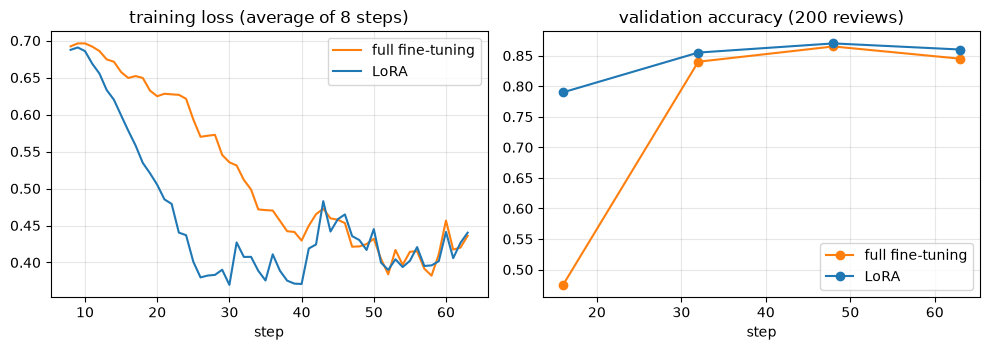

full fine-tuning  training loss: first 8 steps 0.692 -> last 8 steps 0.436 | chosen step 48 | validation (1,000) 0.860
LoRA              training loss: first 8 steps 0.688 -> last 8 steps 0.440 | chosen step 48 | validation (1,000) 0.880


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for name, colour in (("full fine-tuning", "tab:orange"), ("LoRA", "tab:blue")):
    s, l = zip(*methods[name]["train_loss_curve"])
    smooth = np.convolve(l, np.ones(8) / 8, mode="valid")
    axes[0].plot(s[7:], smooth, color=colour, label=name)
    cs, ca = zip(*methods[name]["val_checkpoints"])
    axes[1].plot(cs, ca, "o-", color=colour, label=name)
axes[0].set_title("training loss (average of 8 steps)"); axes[0].set_xlabel("step")
axes[1].set_title("validation accuracy (200 reviews)"); axes[1].set_xlabel("step")
for a in axes: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()
for name in ("full fine-tuning", "LoRA"):
    l = [v for _, v in methods[name]["train_loss_curve"]]
    print(f"{name:<17} training loss: first 8 steps {np.mean(l[:8]):.3f} -> last 8 steps {np.mean(l[-8:]):.3f} | "
          f"chosen step {methods[name]['settings']['chosen_step']} | validation (1,000) {methods[name]['val']['accuracy']:.3f}")

Both runs started at a training loss near ln 2 (0.692 and 0.688 over the first 8 steps, the untrained-head value from Note 8.4) and ended at 0.436 and 0.440 over the last 8 steps. LoRA's loss fell faster early on, mostly because of its larger learning rate, and its first checkpoint was already far above chance, while full fine-tuning's was still at chance. Both peaked on validation at step 48 and dipped slightly at the end: a mild sign that one epoch was about right, and that checkpoint selection mattered.

A note on what we *didn't* record: validation **loss**. Validation accuracy only counts right and wrong; validation loss also shows whether the model is becoming over-confident on the reviews it gets wrong, often an earlier sign of overfitting. Recording it costs nothing extra during evaluation, and an experiment record should include it. That's a lesson for the next run, not something to invent now.

> **Key terms**
> - **Training loss:** the loss on the batches being trained on; shows whether the model fits its training data.
> - **Validation loss / accuracy:** the same measures on held-out data; shows whether learning generalises.

## 3. Task-Specific Metrics

Our task's metrics are accuracy, recall on each class, and F1 for the positive class (Note 8.2). Any accuracy measured on 1,000 reviews is uncertain, so we add a **95% confidence interval**: a range that, by a standard calculation (the Wilson interval), is likely to contain the accuracy we'd see on unlimited reviews like these.

In [7]:
def wilson(k, n, z=1.96):
    """95% confidence interval for a proportion (Wilson score interval)."""
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

rows = []
for name, r in methods.items():
    pred = np.array(r["test_pred"])
    k = int((pred == test_y).sum())
    lo, hi = wilson(k, len(test_y))
    rows.append({"method": name, "accuracy": k / len(test_y), "95% interval": f"{lo:.3f}-{hi:.3f}",
                 "recall neg": r["test"]["recall_neg"], "recall pos": r["test"]["recall_pos"], "F1 pos": r["test"]["f1_pos"]})
table = pd.DataFrame(rows).set_index("method")
print(table.round(3).to_string())

                                         accuracy 95% interval  recall neg  recall pos  F1 pos
method                                                                                        
majority class                              0.485  0.454-0.516       1.000       0.000   0.000
TF-IDF, 1,000 labels                        0.828  0.803-0.850       0.821       0.835   0.833
TF-IDF, all labels                          0.913  0.894-0.929       0.920       0.907   0.915
SST-2 model, off the shelf                  0.873  0.851-0.892       0.856       0.889   0.878
frozen DistilBERT + logistic regression     0.837  0.813-0.859       0.835       0.839   0.841
full fine-tuning                            0.834  0.810-0.856       0.874       0.796   0.832
LoRA                                        0.834  0.810-0.856       0.829       0.839   0.839


The intervals are roughly four to five points wide. Full fine-tuning and LoRA both score 0.834, with intervals of 0.810–0.856. The off-the-shelf SST-2 model scores 0.873 (0.851–0.892), and TF-IDF with all labels 0.913 (0.894–0.929). Overlapping intervals don't settle a comparison on their own; for that we use the paired sign test (Section 6), which is more sensitive because it compares methods review by review.

The recall columns show a difference the accuracies hide. Full fine-tuning catches negative reviews well (0.874) but misses more positive ones (0.796), while LoRA is balanced (0.829 and 0.839). If the feature's purpose were to catch unhappy customers, full fine-tuning's profile might even be preferable, despite equal accuracy. Metrics should match what the application needs (Note 7.5).

> **Key terms**
> - **Confidence interval:** a range likely to contain the true value of a measured quantity; here, accuracy on unlimited data.
> - **Wilson interval:** a standard way to compute a confidence interval for a proportion.

> **Check yourself 1.** Two models' 95% intervals overlap. Does that prove there's no real difference between them? What would you do instead?

## 4. Qualitative Evaluation and Error Analysis

### 4.1 Who gets what wrong

Metrics count errors; error analysis looks at them. First, how much do methods agree on *which* reviews are hard? The table counts test reviews that both the row's and the column's method got wrong. The diagonal shows each method's own number of errors.

In [8]:
names = ["TF-IDF, 1,000 labels", "frozen DistilBERT + logistic regression", "SST-2 model, off the shelf",
         "full fine-tuning", "LoRA", "TF-IDF, all labels"]
short = {"TF-IDF, 1,000 labels": "TF-IDF 1k", "frozen DistilBERT + logistic regression": "frozen",
         "SST-2 model, off the shelf": "SST-2", "full fine-tuning": "full FT", "LoRA": "LoRA", "TF-IDF, all labels": "TF-IDF all"}
wrong = {n: np.array(methods[n]["test_pred"]) != test_y for n in names}
overlap = pd.DataFrame([[int((wrong[a] & wrong[b]).sum()) for b in names] for a in names],
                       index=[short[n] for n in names], columns=[short[n] for n in names])
print("test reviews both methods got wrong (diagonal: each method's own errors):")
print(overlap.to_string())

test reviews both methods got wrong (diagonal: each method's own errors):
            TF-IDF 1k  frozen  SST-2  full FT  LoRA  TF-IDF all
TF-IDF 1k         172      74     46       67    68          68
frozen             74     163     65       85   106          47
SST-2              46      65    127       77    84          31
full FT            67      85     77      166   112          42
LoRA               68     106     84      112   166          44
TF-IDF all         68      47     31       42    44          87


Full fine-tuning and LoRA each get 166 reviews wrong, and 112 of those are shared. They're the same model architecture trained on the same data, so they fail in similar places. LoRA also shares 106 errors with the frozen encoder: all three use the same pretrained DistilBERT representation, which seems to struggle with the same reviews. The SST-2 model and TF-IDF with all labels share far fewer errors with the others: they fail *differently*.

### 4.2 Patterns

In [9]:
both_ft = wrong["full fine-tuning"] & wrong["LoRA"]
print(f"wrong for both fine-tuned models: {both_ft.sum()} | of those, right for the SST-2 model: {(both_ft & ~wrong['SST-2 model, off the shelf']).sum()}")
print(f"wrong for every one of the {len(names)} methods: {np.logical_and.reduce([wrong[n] for n in names]).sum()}")
tok = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
n_tok = np.array([len(ids) for ids in tok(test_x, add_special_tokens=True)["input_ids"]])
for label, mask in (("fits in 128 tokens", n_tok <= 128), ("longer than 128 tokens", n_tok > 128)):
    accs = " | ".join(f"{short[n]} {1 - wrong[n][mask].mean():.3f}" for n in names)
    print(f"{label:<23} ({mask.sum():>3} reviews): {accs}")

wrong for both fine-tuned models: 112 | of those, right for the SST-2 model: 46
wrong for every one of the 6 methods: 12


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (903 > 512). Running this sequence through the model will result in indexing errors


fits in 128 tokens      (121 reviews): TF-IDF 1k 0.818 | frozen 0.909 | SST-2 0.917 | full FT 0.884 | LoRA 0.876 | TF-IDF all 0.909
longer than 128 tokens  (879 reviews): TF-IDF 1k 0.829 | frozen 0.827 | SST-2 0.867 | full FT 0.827 | LoRA 0.828 | TF-IDF all 0.914


Of the 112 reviews both fine-tuned models got wrong, the SST-2 model got 46 right, so those are worth reading. Only 12 reviews defeat all six methods, perhaps hard or even mislabelled ones. Splitting by length shows something else. On the 121 test reviews that fit within 128 tokens, the DistilBERT-based methods all do well (0.876–0.917). On the 879 longer reviews, which head+tail truncation had to cut, every method that reads only 128 tokens drops, while TF-IDF with all labels, which reads every word, holds at 0.914. Part of the gap between the transformer methods and that TF-IDF model is simply that TF-IDF saw the whole review.

Here are the first three reviews that both fine-tuned models got wrong but the SST-2 model got right:

In [10]:
idx = np.where(both_ft & ~wrong["SST-2 model, off the shelf"])[0][:3]    # the first three such reviews
for i in idx:
    print(f"\ntrue: {'positive' if test_y[i] else 'negative'} | {n_tok[i]} tokens")
    print("  " + test_x[i][:280] + " ...")


true: positive | 367 tokens
  That's a bad, raunchy, predictable, tacky, salacious soap opera? "The Best of Everything" is just such a guilty pleasure for me, something along the lines of "Valley of the Dolls". I mean, "Best" has everything. Somebody gets pregnant out of wedlock (when's the last time you hear ...

true: positive | 175 tokens
  The main reason to check this one out is to watch Laura Gemser in all her glory.  That's reason enough for me.  She heads to Africa as guests of another rich guy that seems to be all over these films. Huge mansion near the jungle. Hunters staying around for parties when they aren ...

true: positive | 281 tokens
  With all the shoot em up, blood horror movies that have come our way in the last little while "Saw, Hostal, Saw 2, The Hills have eyes" Yes, they have their place, don't get me wrong! I went to see "When a stranger calls" with my buddy the other night! Why? Because it's a remake  ...


All three are positive reviews written with plenty of negative-sounding words. One calls the film "a bad, raunchy, predictable, tacky, salacious soap opera" and then a "guilty pleasure". One praises the film for a reason other than its quality. One opens by comparing it with gory horror films. The fine-tuned models, trained on just 1,000 reviews, seem to have learned that negative words mean a negative review. The SST-2 model, trained on many more labelled sentences, handles the reversal. That points to a concrete improvement: more training examples of exactly this kind of review.

> **Key terms**
> - **Error analysis:** examining which examples a model gets wrong, and why.
> - **Error overlap:** how many errors two models share; low overlap means they fail differently, which also makes them good candidates to combine.

> **Common mistake:** choosing error examples by hand because they "look interesting". Choose them by a rule (here, the first three that meet a condition), or you may be picking the examples that support a story you already believe.

## 5. Detecting Overfitting and Catastrophic Forgetting

### 5.1 The validation–test gap

Settings (regularisation, checkpoints) were chosen on validation, so each method's validation score is slightly optimistic, and the test score is the honest one. A *large* gap between them warns that a method was tuned to its validation data, a form of overfitting to the selection process.

In [11]:
for name in ("TF-IDF, 1,000 labels", "frozen DistilBERT + logistic regression", "full fine-tuning", "LoRA"):
    r = methods[name]
    print(f"{name:<40} validation {r['val']['accuracy']:.3f} | test {r['test']['accuracy']:.3f} | gap {r['val']['accuracy'] - r['test']['accuracy']:+.3f}")

TF-IDF, 1,000 labels                     validation 0.866 | test 0.828 | gap +0.038
frozen DistilBERT + logistic regression  validation 0.850 | test 0.837 | gap +0.013
full fine-tuning                         validation 0.860 | test 0.834 | gap +0.026
LoRA                                     validation 0.880 | test 0.834 | gap +0.046


All four methods that chose settings on validation score lower on test, by between 0.013 and 0.046. LoRA has the largest gap (0.880 → 0.834): its validation score looked best among the 1,000-label methods, but on test it is level with the rest. That's why the test set, not validation, decides comparisons, and why a single validation result should never be trusted on its own (Section 7 shows how much results vary).

### 5.2 Forgetting

In [12]:
f4, f5 = methods["full fine-tuning"]["forgetting_word_guessing_loss"], methods["LoRA"]["forgetting_word_guessing_loss"]
print(f"word-guessing loss on 200 held-out reviews: pretrained {f4['pretrained']} | full fine-tuning {f4['fine-tuned']} | "
      f"LoRA merged {f5['LoRA merged in']} | LoRA switched off: unchanged by construction")

word-guessing loss on 200 held-out reviews: pretrained 3.381 | full fine-tuning 4.07 | LoRA merged 3.461 | LoRA switched off: unchanged by construction


The forgetting measure from Note 8.1 tells a clear story: full fine-tuning raised the word-guessing loss from 3.381 to 4.07, while LoRA, even merged, raised it only to 3.461, and with the adapter switched off it is unchanged. For this application we don't need word-guessing, so forgetting doesn't count against either model here. In applications where the adapted model must keep general abilities, it would weigh heavily in LoRA's favour.

> **Check yourself 2.** Why is a validation–test gap expected for every method that chose settings on validation, and when should a gap worry you?

## 6. Comparing Across the Ladder: Performance, Trainable Parameters, Time, Memory

### 6.1 The whole ladder

Here is every method with what it used and what it cost. Training times were measured in each note on this machine and printed with units; compare them relative to each other, since they vary between machines and runs.

In [13]:
cost = {"majority class": (0, "-"), "TF-IDF, 1,000 labels": (methods["TF-IDF, 1,000 labels"]["trained_parameters"], methods["TF-IDF, 1,000 labels"]["train_time"]),
        "TF-IDF, all labels": (methods["TF-IDF, all labels"]["trained_parameters"], methods["TF-IDF, all labels"]["train_time"]),
        "SST-2 model, off the shelf": (0, "-"),
        "frozen DistilBERT + logistic regression": (methods["frozen DistilBERT + logistic regression"]["trained_parameters"], methods["frozen DistilBERT + logistic regression"]["train_time"]),
        "full fine-tuning": (methods["full fine-tuning"]["trainable_parameters"], methods["full fine-tuning"]["train_time"]),
        "LoRA": (methods["LoRA"]["trainable_parameters"], methods["LoRA"]["train_time"])}
mem = {"full fine-tuning": f"{methods['full fine-tuning']['training_memory_estimate_mb']} MB",
       "LoRA": f"{methods['LoRA']['training_memory_estimate_mb']} MB"}
comp = pd.DataFrame([{"method": n, "labels": methods[n]["labels_used"], "trained params": cost[n][0],
                      "train time": cost[n][1], "training memory": mem.get(n, "-"),
                      "test acc": methods[n]["test"]["accuracy"]} for n in cost]).set_index("method")
print(comp.to_string())

                                         labels  trained params train time training memory  test acc
method                                                                                              
majority class                             1000               0          -               -     0.485
TF-IDF, 1,000 labels                       1000           29755      0.1 s               -     0.828
TF-IDF, all labels                        22404          399451      4.2 s               -     0.913
SST-2 model, off the shelf                    0               0          -               -     0.873
frozen DistilBERT + logistic regression    1000             769      9.9 s               -     0.837
full fine-tuning                           1000        66955010       58 s         1071 MB     0.834
LoRA                                       1000          739586       45 s          280 MB     0.834


The costs span orders of magnitude:
- TF-IDF trains tens or hundreds of thousands of word weights in seconds.
- The frozen encoder trains 769 weights after one feature pass.
- LoRA trains 739,586 parameters, full fine-tuning all 66,955,010. Their estimated training memory is 280 MB and 1071 MB.
- The SST-2 model trains nothing on IMDb. Note, though, that it isn't free in an absolute sense: someone else fine-tuned it on a large labelled dataset, and we inherit that work.

### 6.2 Is anything better than the best cheap baseline?

The strongest method using no more than 1,000 IMDb labels is the SST-2 model off the shelf. We compare everything with it on the same test reviews:

In [14]:
best_baseline = "SST-2 model, off the shelf"                                 # the strongest method using <= 1,000 labels
ref = np.array(methods[best_baseline]["test_pred"]) == test_y
for name in ("full fine-tuning", "LoRA", "frozen DistilBERT + logistic regression", "TF-IDF, 1,000 labels", "TF-IDF, all labels"):
    right = np.array(methods[name]["test_pred"]) == test_y
    a, b = int((right & ~ref).sum()), int((~right & ref).sum())
    print(f"{name:<40} vs {best_baseline}: only it right {a:>3} | only baseline right {b:>3} | p = {binomtest(a, a + b).pvalue:.2g}")

full fine-tuning                         vs SST-2 model, off the shelf: only it right  50 | only baseline right  89 | p = 0.0012
LoRA                                     vs SST-2 model, off the shelf: only it right  43 | only baseline right  82 | p = 0.00062
frozen DistilBERT + logistic regression  vs SST-2 model, off the shelf: only it right  62 | only baseline right  98 | p = 0.0055
TF-IDF, 1,000 labels                     vs SST-2 model, off the shelf: only it right  81 | only baseline right 126 | p = 0.0022
TF-IDF, all labels                       vs SST-2 model, off the shelf: only it right  96 | only baseline right  56 | p = 0.0015


Every 1,000-label method is significantly worse than the off-the-shelf model:
- full fine-tuning: 50 against 89 reviews, p = 0.0012;
- LoRA: 43 against 82, p = 0.00062;
- the frozen encoder and TF-IDF with 1,000 labels likewise.

Only TF-IDF trained on *all* 22,404 labels beats it (96 against 56, p = 0.0015). The picture in one chart:

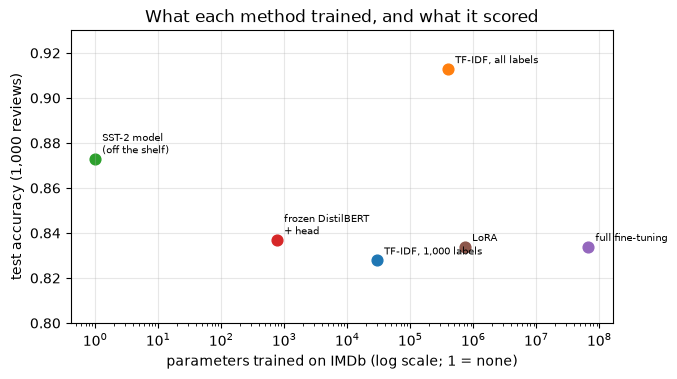

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for n in cost:
    if n == "majority class":
        continue
    x = max(cost[n][0], 1)
    ax.scatter(x, methods[n]["test"]["accuracy"], s=60)
    ax.annotate(n.replace(", off the shelf", "\n(off the shelf)").replace(" + logistic regression", "\n+ head"),
                (x, methods[n]["test"]["accuracy"]), fontsize=7, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("parameters trained on IMDb (log scale; 1 = none)"); ax.set_ylabel("test accuracy (1,000 reviews)")
ax.set_title("What each method trained, and what it scored"); ax.grid(alpha=0.3); ax.set_ylim(0.8, 0.93); plt.show()

The chart makes the lesson hard to miss. Training more parameters on the same 1,000 labels didn't buy accuracy: the frozen encoder (769 parameters), LoRA (739,586) and full fine-tuning (66,955,010) all land at about the same height. The two winners got their advantage from *more labelled data*: the SST-2 model indirectly, through someone else's large dataset, and TF-IDF directly, from all 22,404 IMDb labels.

> **Check yourself 3.** A colleague concludes "fine-tuning doesn't work for sentiment analysis". What's wrong with that conclusion, given what was and wasn't varied here?

## 7. Reproducibility and Experiment Tracking

### 7.1 How much do results vary?

Every adapted model here comes from a single training run. How much might a result change with a different random draw? We can't afford to retrain the Transformers many times on a CPU, but we can measure the variation for the cheapest rung: TF-IDF trained on five different random sets of 1,000 training reviews, scored on the same validation reviews.

In [16]:
val_x, val_y = imdb["val_eval"]
all_x, all_y = imdb["train"]
rng = np.random.default_rng(0)
accs = []
for draw in range(5):                                                        # 5 different sets of 1,000 training reviews
    idx = rng.choice(len(all_x), 1000, replace=False)
    vec = TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)
    X = vec.fit_transform([all_x[i] for i in idx])
    clf = LogisticRegression(C=3, max_iter=2000).fit(X, all_y[idx])
    accs.append((clf.predict(vec.transform(val_x)) == val_y).mean())
print("TF-IDF, 1,000 labels, five different training draws: validation accuracy",
      [round(float(a), 3) for a in accs], f"| spread {min(accs):.3f}-{max(accs):.3f}")

TF-IDF, 1,000 labels, five different training draws: validation accuracy [0.846, 0.853, 0.84, 0.851, 0.859] | spread 0.840-0.859


Validation accuracy ranges from 0.840 to 0.859 across the five draws, about two points, purely from *which* 1,000 reviews were labelled. Fine-tuning runs also vary with initialisation, shuffling and dropout. So differences of one or two points between single runs, like LoRA's 0.880 against full fine-tuning's 0.860 on validation, shouldn't be read as real without repeated runs or a paired test. The paired test said there was no difference on test (Note 8.5).

### 7.2 Tracking experiments

Each note saved its settings, data fingerprints, costs and results to a file. Collecting them into one table, and saving it, is the beginning of **experiment tracking**: a permanent, comparable record of every run. Tools such as MLflow and Weights & Biases do this at scale, but the principle is the same.

In [17]:
tracking = pd.DataFrame([{"note": "8.3" if n in files["8.3"]["rungs"] else ("8.4" if n == "full fine-tuning" else "8.5"),
                          "method": n, "setting": json.dumps(methods[n].get("settings", methods[n].get("setting", ""))),
                          "val_acc": methods[n]["val"]["accuracy"], "test_acc": methods[n]["test"]["accuracy"]} for n in methods])
os.makedirs("results", exist_ok=True)
tracking.to_csv("results/experiments.csv", index=False)
print(tracking[["note", "method", "val_acc", "test_acc"]].to_string(index=False))
print("environment:", {"python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__, "peft": peft.__version__})

note                                  method  val_acc  test_acc
 8.3                          majority class    0.505     0.485
 8.3                    TF-IDF, 1,000 labels    0.866     0.828
 8.3                      TF-IDF, all labels    0.921     0.913
 8.3              SST-2 model, off the shelf    0.888     0.873
 8.3 frozen DistilBERT + logistic regression    0.850     0.837
 8.4                        full fine-tuning    0.860     0.834
 8.5                                    LoRA    0.880     0.834
environment: {'python': '3.12.15', 'torch': '2.14.1', 'transformers': '5.20.1', 'peft': '0.21.2'}


The table lists every method with its note, settings, validation and test accuracy, and is saved as `results/experiments.csv`, alongside the environment (Python 3.12.15, PyTorch 2.14.1, Transformers 5.20.1, PEFT 0.21.2). With the fixed split, the fingerprints and the pinned versions in `requirements.txt`, anyone can rerun these notes and check the numbers.

> **Key terms**
> - **Run-to-run variation:** differences in results caused by randomness in data sampling, initialisation and training order.
> - **Experiment tracking:** recording each run's settings, data, code versions and results so that runs can be compared and reproduced.

## 8. The Keep-or-Reject Decision

A decision should follow rules written *before* looking at which model looks best. Otherwise it's easy to find reasons to keep the model you hoped would win. Ours, stated in the cell below before the decision is computed:
- **R1:** an adapted model must beat the strongest baseline that uses no more labels, on the same test reviews, with sign-test p < 0.05.
- **R2:** it must fit the deployment budget (CPU inference, one model per task). All candidates do.
- **R3:** it must not damage abilities we still need. Word-guessing isn't needed here.

In [18]:
rules = {
    "R1": "it must beat the strongest baseline that uses no more labels, on the same test reviews, with sign-test p < 0.05",
    "R2": "it must fit the deployment budget: CPU inference, one model per task",
    "R3": "it must not damage abilities we still need (we do not need word-guessing here)",
}
ref = np.array(methods[best_baseline]["test_pred"]) == test_y
decision = {}
for name in ("full fine-tuning", "LoRA"):
    right = np.array(methods[name]["test_pred"]) == test_y
    a, b = int((right & ~ref).sum()), int((~right & ref).sum())
    p = binomtest(a, a + b).pvalue
    r1 = a > b and p < 0.05
    decision[name] = "keep" if r1 else "reject"
    print(f"{name:<17} R1: {'passes' if r1 else 'fails'} ({a} vs {b}, p = {p:.2g}) -> {decision[name]}")

full fine-tuning  R1: fails (50 vs 89, p = 0.0012) -> reject
LoRA              R1: fails (43 vs 82, p = 0.00062) -> reject


Both adapted models fail R1: each is significantly *worse* than the off-the-shelf SST-2 model, not better. The decision is to **reject** both and, under a 1,000-label budget, use the SST-2 model as it is. If all 22,404 labels can be used, TF-IDF with all labels is better still.

Rejecting a model you spent effort on is not a failed project. It's the evaluation doing its job. The experiments answered a real question ("does adapting DistilBERT on 1,000 IMDb labels beat what we can get for free?") with a clear, defensible "no, not in this setup". And the error analysis showed what might change the answer.

## 9. Documenting Findings, Limitations and Next Steps

Finally, we write the decision down, extending Note 7.7's decision record with everything this module measured:

In [19]:
record = {
    "question": "Does adapting DistilBERT on 1,000 labelled IMDb reviews beat the alternatives?",
    "data": {"split_fingerprints": expected, "train_subset_fingerprint": fingerprint(train_x),
             "test_reviews": len(test_y)},
    "results_test_accuracy": {n: methods[n]["test"]["accuracy"] for n in methods},
    "decision": {**decision, "use instead (1,000-label budget)": best_baseline + " (no IMDb labels needed)",
                 "if all 22,404 labels can be used": "TF-IDF, all labels (best test accuracy, beats SST-2 with p = 0.0015)"},
    "limitations": ["single training run per adapted model (no seed repeats)",
                    "1,000 training reviews, 1 epoch, 128 tokens (head+tail)",
                    "CPU-sized experiment; learning rates not tuned on validation"],
    "next steps": ["fine-tune with more labels (TF-IDF with all labels reached the best test accuracy)",
                   "longer inputs (Note 7.7 found 512 tokens better than 256 for the SST-2 model)",
                   "repeat training over several seeds before claiming small differences",
                   "confirm any new winner on a fresh test sample, since this one has now been used for the decision"],
}
with open("results/8.7-decision.json", "w") as f:
    json.dump(record, f, indent=1)
print(json.dumps(record, indent=1))

{
 "question": "Does adapting DistilBERT on 1,000 labelled IMDb reviews beat the alternatives?",
 "data": {
  "split_fingerprints": {
   "train": "fb3a1229f951",
   "val_eval": "9934ffeaac91",
   "test_eval": "fc9fa98701bc"
  },
  "train_subset_fingerprint": "7b0ca50110ca",
  "test_reviews": 1000
 },
 "results_test_accuracy": {
  "majority class": 0.485,
  "TF-IDF, 1,000 labels": 0.828,
  "TF-IDF, all labels": 0.913,
  "SST-2 model, off the shelf": 0.873,
  "frozen DistilBERT + logistic regression": 0.837,
  "full fine-tuning": 0.834,
  "LoRA": 0.834
 },
 "decision": {
  "full fine-tuning": "reject",
  "LoRA": "reject",
  "use instead (1,000-label budget)": "SST-2 model, off the shelf (no IMDb labels needed)",
  "if all 22,404 labels can be used": "TF-IDF, all labels (best test accuracy, beats SST-2 with p = 0.0015)"
 },
 "limitations": [
  "single training run per adapted model (no seed repeats)",
  "1,000 training reviews, 1 epoch, 128 tokens (head+tail)",
  "CPU-sized experiment; le

The record states the question, the exact data (by fingerprint), every method's test accuracy, the decision with its alternative, the **limitations** that bound the conclusion, and **next steps** that could change it:
- **Limitations:** a single run per adapted model; only 1,000 reviews, one epoch and 128 tokens; a CPU-sized experiment with learning rates not tuned on validation.
- **Next steps:**
  - more labels, the clearest lever in our results;
  - longer inputs, since every 128-token method lost accuracy on long reviews;
  - repeated runs before claiming small differences;
  - a fresh test sample for any new winner, since this one has now been used to make a decision.

A reader of this record in six months can see what was concluded, how much to trust it, and what to try next.

> **Common mistake:** writing up only the winning number. A useful record includes what was compared, on which data, what was rejected and why, what the conclusion depends on, and what would change it.

## Putting It All Together

Let's reassemble the evaluation, and with it Module 8.

We loaded the results of seven methods, checked by fingerprint that all used the same split and the same 1,000 training reviews, and asked seven questions:
- **Training behaved sensibly:** the loss fell from about ln 2 to 0.436 and 0.440 in the two fine-tuning runs, and validation peaked at step 48 before dipping slightly.
- **Task metrics with 95% intervals:** both adapted models scored 0.834 (0.810–0.856), with different recall profiles.
- **Error analysis:** the two fine-tuned models shared 112 of their 166 errors, struggled on reviews longer than 128 tokens, and misread positive reviews full of negative words, which the SST-2 model handled.
- **Overfitting and forgetting:** every method lost a little between validation and test (LoRA most, 0.046), and full fine-tuning forgot more (word-guessing loss 4.07) than LoRA (3.461).
- **Comparison:** across the ladder, training more parameters on the same 1,000 labels didn't help, and every 1,000-label method was significantly worse than the off-the-shelf SST-2 model.
- **Variation:** TF-IDF varied by about two points across five draws of training data; results were tracked in `results/experiments.csv`.
- **Decision:** by rules set in advance, both adapted models were **rejected**: use the SST-2 model under a 1,000-label budget, or TF-IDF with all labels if they're available. The decision was recorded with its limitations and next steps.

Module 8 asked how to adapt pretrained models without updating every parameter, and how to prepare data for reliable adaptation.
- **8.1** mapped the adaptation spectrum.
- **8.2** prepared the data (and found that keeping the end of a review mattered).
- **8.3** built the baselines.
- **8.4** fine-tuned fully.
- **8.5** showed LoRA matching full fine-tuning with about 1% of the trainable parameters and less forgetting.
- **8.6** carried the same ideas to large language models.
- **8.7** showed how to decide, honestly, whether any of it was worth it.

The adapted models didn't win here, and knowing that, with evidence, is the outcome a careful engineer should want.

| Method | Labels | Trained params | Test (1,000) | vs SST-2 off the shelf | Decision |
|---|---|---|---|---|---|
| TF-IDF | 1,000 | 29,755 | 0.828 | worse, p = 0.0022 | — |
| Frozen DistilBERT + head | 1,000 | 769 | 0.837 | worse, p = 0.0055 | — |
| Full fine-tuning | 1,000 | 66,955,010 | 0.834 | worse, p = 0.0012 | reject |
| LoRA | 1,000 | 739,586 | 0.834 | worse, p = 0.00062 | reject |
| SST-2 model, off the shelf | 0 | 0 | 0.873 | — | use (1,000-label budget) |
| TF-IDF | 22,404 | 399,451 | 0.913 | better, p = 0.0015 | use if all labels available |

> 🖼 *IMAGE 8.7.2 — The Verdict.* A white-background courtroom-style card titled "Keep or reject?". On the left, two defendants as model icons, "full fine-tuning (0.834)" in orange and "LoRA (0.834)" in blue, each with a red stamp "REJECTED — worse than SST-2 off the shelf (p = 0.0012 / 0.00062)". On the right, two green-ticked cards: "SST-2 off the shelf 0.873: use with a 1,000-label budget" and "TF-IDF, all labels 0.913: use if all labels are available". At the bottom, a scroll labelled "decision record: data fingerprints · results · limitations (single runs, 128 tokens, 1,000 labels) · next steps (more labels, longer inputs, repeated runs, fresh test set)". Takeaway: a rejected model, with evidence and a record, is a successful evaluation.

## Summary

- Evaluating an adapted model answers several questions: training behaviour, metrics with uncertainty, errors, overfitting and forgetting, comparison and cost, reproducibility, and the decision itself.
- All results files used the same split and the same 1,000 training reviews (checked by fingerprint).
- **Training curves:** loss fell from about ln 2 to 0.436 and 0.440 in the two runs; validation accuracy peaked at step 48. Validation loss wasn't recorded and should be next time.
- **Metrics with 95% intervals:** full fine-tuning and LoRA both 0.834 (0.810–0.856); SST-2 off the shelf 0.873 (0.851–0.892); TF-IDF with all labels 0.913 (0.894–0.929).
- **Error analysis:** the fine-tuned models shared 112 of 166 errors; methods reading 128 tokens dropped on long reviews; positive reviews full of negative words fooled the fine-tuned models but not the SST-2 model.
- **Overfitting signs:** validation-to-test drops of 0.013–0.046 (LoRA largest). **Forgetting:** 4.07 for full fine-tuning against 3.461 for LoRA (pretrained 3.381).
- **Comparison:** more trained parameters on the same 1,000 labels didn't help; every 1,000-label method was significantly worse than the off-the-shelf SST-2 model; only TF-IDF with all labels beat it.
- **Variation:** five TF-IDF training draws ranged 0.840–0.859 on validation. Results were tracked in `results/experiments.csv`.
- **Decision**, by rules set in advance: reject both adapted models; use the SST-2 model (or TF-IDF with all labels). The decision record lists limitations and next steps.

## Glossary

| Term | Meaning |
|---|---|
| Training loss | Loss on the training batches. |
| Validation loss / accuracy | Loss or accuracy on held-out data, used to monitor generalisation. |
| Confidence interval | A range likely to contain the true value of a measured quantity. |
| Wilson interval | A standard confidence interval for a proportion. |
| Error analysis | Examining which examples a model gets wrong and why. |
| Error overlap | The number of errors two models share. |
| Validation–test gap | The drop from validation to test score, partly due to selecting on validation. |
| Paired sign test | Comparing two models on the same examples by counting where only one is right. |
| Run-to-run variation | Differences between runs caused by randomness. |
| Experiment tracking | Recording each run's settings, data, versions and results. |
| Keep-or-reject rule | A criterion, set in advance, for adopting a model. |
| Decision record | A written record of a decision with its evidence, limitations and next steps. |

## Answers to Check Yourself

**1.** No. Overlapping 95% intervals are consistent with a real difference, because each interval reflects the uncertainty of one model on its own, ignoring that both were scored on the *same* reviews. A paired test, such as the sign test on the reviews where exactly one model is right, uses that pairing and can detect differences that overlapping intervals hide.

**2.** Choosing settings or checkpoints on validation picks whichever option was luckiest there, so part of the validation score is that luck, and it doesn't carry over to test. A small drop is therefore normal. A gap should worry you when it's much larger than the run-to-run variation you'd expect (here about two points), or when it's large for one method but not others evaluated the same way. That suggests the method was tuned to quirks of the validation set, or that something leaked.

**3.** It generalises far beyond what was tested. We fine-tuned one small model, on only 1,000 labels, for one epoch, with 128 tokens of each review and untuned learning rates, on a CPU. The comparison showed that, *in this setup*, fine-tuning didn't beat a model already fine-tuned on much more sentiment data, or TF-IDF with all labels. With more labels, longer inputs or a better-tuned recipe, the result could change. The correct conclusion is limited to the conditions tested, which is exactly what the decision record's limitations say.